# Tutorial 4b: Raytracing Aspheres and Freeforms

**In this tutorial:** surfaces beyond the sphere, including conics, even and odd aspheres, and freeforms.


This tutorial shows how even aspheres can be modeled in Optiland. We will first assess a simple spherical lens, then compare it to an even asphere.

In [1]:
import numpy as np

from optiland import analysis, optic

1. Spherical Singlet

Let's define a simple singlet:

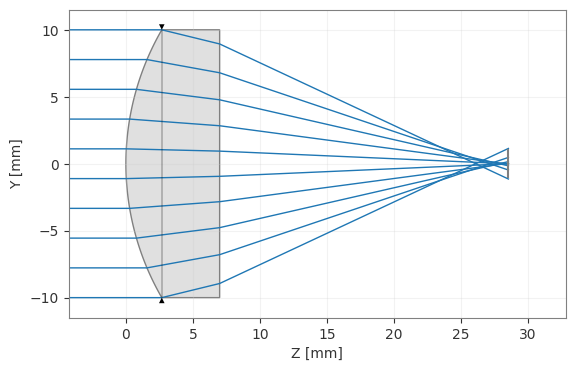

(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

In [2]:
spherical = optic.Optic()

# add surfaces
spherical.surfaces.add(index=0, radius=np.inf, thickness=np.inf)
spherical.surfaces.add(
    index=1,
    thickness=7,
    radius=20.0,
    is_stop=True,
    material="N-SF11",
)
spherical.surfaces.add(index=2, thickness=21.56201105)
spherical.surfaces.add(index=3)

# add aperture
spherical.set_aperture(aperture_type="EPD", value=20.0)

# add field
spherical.fields.set_type(field_type="angle")
spherical.fields.add(y=0)

# add wavelength
spherical.wavelengths.add(value=0.587, is_primary=True)

spherical.updater.update_paraxial()

spherical.draw(num_rays=10)

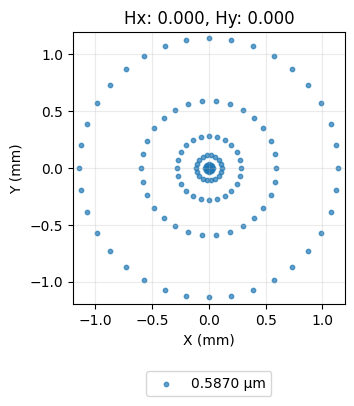

(<Figure size 1200x400 with 1 Axes>,
 [<Axes: title={'center': 'Hx: 0.000, Hy: 0.000'}, xlabel='X (mm)', ylabel='Y (mm)'>])

In [3]:
spot = analysis.SpotDiagram(spherical)
spot.view()

As we can see, this lens shows a significant amount of spherical aberration, as is typical for such a lens.

2. Aspherical Singlet

Let's now define an asphere which has improved spherical aberration performance.

We define the "surface_type" attribute as "even_asphere" and we supply a list of coefficients of the aspheric terms. The aspheric surface sag equation is

$z(r) = \frac{r^2}{R(1 + \sqrt{1 - (1 + \kappa)\frac{r^2}{R^2}})} + \alpha_2r^2 + \alpha_4r^4 + \alpha_6r^6 + \ldots$

where $z$ is the sag, $R$ is the radius of curvature, $r$ is the radial distance from the optical axis, and $\alpha_2, \alpha_4, \alpha_6, \ldots$ are the coefficients of the asphere. The coefficient list provided to the surface is simply $[\alpha_2, \alpha_4, \alpha_6, \ldots]$.

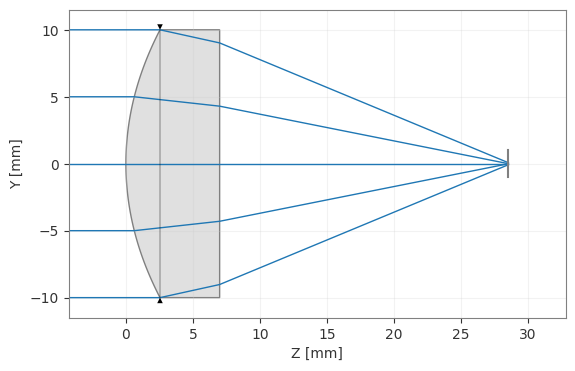

(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

In [4]:
asphere = optic.Optic()

# add surfaces
asphere.surfaces.add(index=0, radius=np.inf, thickness=np.inf)
asphere.surfaces.add(
    index=1,
    thickness=7,
    radius=20.0,
    is_stop=True,
    material="N-SF11",
    surface_type="even_asphere",
    conic=0.0,
    coefficients=[
        -2.248851e-4,
        -4.690412e-6,
        -6.404376e-8,
    ],  # <-- coefficients for asphere
)
asphere.surfaces.add(index=2, thickness=21.56201105)
asphere.surfaces.add(index=3)

# add aperture
asphere.set_aperture(aperture_type="EPD", value=20.0)

# add field
asphere.fields.set_type(field_type="angle")
asphere.fields.add(y=0)

# add wavelength
asphere.wavelengths.add(value=0.587, is_primary=True)

asphere.updater.update_paraxial()

asphere.draw(num_rays=5)

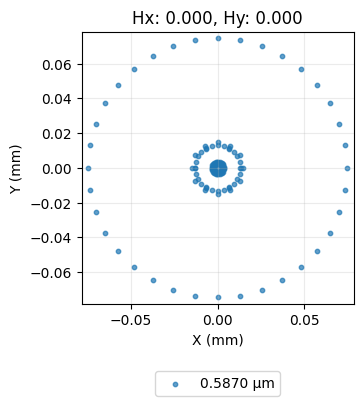

(<Figure size 1200x400 with 1 Axes>,
 [<Axes: title={'center': 'Hx: 0.000, Hy: 0.000'}, xlabel='X (mm)', ylabel='Y (mm)'>])

In [5]:
spot = analysis.SpotDiagram(asphere)
spot.view()

We can see that the rays now focus much closer to the optical axis and that the spot size has reduced significantly.

Conclusions:

- This tutorial introduced the even asphere surface type.
- To use an aspheric surface, we simply specify surface_type='even_asphere' and provide the list of aspheric coefficients.

This tutorial used an asphere that had already been optimized for minimal wavefront error. We ignored these details here, but future tutorials will elaborate on the asphere optimization process.


---
## Part 2: Freeform Surfaces



This tutorial demonstrates how freeform surfaces can be modeled in Optiland. Several freeform types are supported, including polynomial and Chebyshev surfaces.

In this tutorial, we will design a unique singlet lens with the following properties:

- rays from on-axis field point intersect the image plane at y=3mm
- RMS spot size is minimized

This is rather unique (and perhaps not all that useful), as rays from the on-axis field point in a standard lens are generally centered on the optical axis.

In [6]:
import numpy as np

from optiland import analysis, optic, optimization

Preparation:

We start by defining a freeform lens class, which has a freeform as its first surface.

The freeform surface is defined as:

$z(x, y) = \frac{r^2}{R \cdot (1 + \sqrt{(1 - (1 + k) \cdot r^2 / R^2)})} + \sum\limits_{i}\sum\limits_{j}{C_{i, j} \cdot x^i \cdot y^j}$

where

- $x$ and $y$ are the local surface coordinates
- $r^2 = x^2 + y^2$
- $R$ is the radius of curvature
- $k$ is the conic constant
- $C_{i, j}$ is the polynomial coefficient for indices $i, j$

In [7]:
from optiland.materials import Material

class Freeform(optic.Optic):
    def __init__(self):
        super().__init__()

        # add surfaces
        self.surfaces.add(index=0, radius=np.inf, thickness=np.inf)

        # ======== Add polynomial freeform here =====================================
        self.surfaces.add(
            index=1,
            radius=100,
            thickness=5,
            surface_type="polynomial",  # <-- surface_type='polynomial'
            is_stop=True,
            material=Material("SF11", catalog="schott"),
            coefficients=[],
        )
        # ===========================================================================

        self.surfaces.add(index=2, thickness=100)
        self.surfaces.add(index=3)

        # add aperture
        self.set_aperture(aperture_type="EPD", value=25)

        # add field
        self.fields.set_type(field_type="angle")
        self.fields.add(y=0)

        # add wavelength
        self.wavelengths.add(value=0.55, is_primary=True)

We simply need to specify the surface type as 'polynomial' to make the first surface a freeform. Note that we did not pass coefficients to the surface, which implies all coefficients will be zero.

Let's generate and view the starting point lens, which will simply be spherical, as the freeform coefficients are all zero.

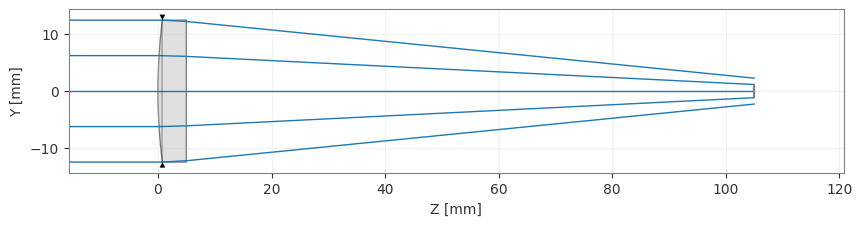

(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

In [8]:
lens = Freeform()
lens.draw(num_rays=5)

We now define the optimization problem. Let's start with the two operands: 1) RMS spot size and 2) real ray y-intercept.

In [9]:
problem = optimization.OptimizationProblem()

# RMS spot size operand
input_data = {
    "optic": lens,
    "surface_number": -1,
    "Hx": 0,
    "Hy": 0,
    "wavelength": 0.55,
    "num_rays": 5,
}
problem.add_operand(
    operand_type="rms_spot_size",
    target=0,
    weight=1,
    input_data=input_data,
)

# Real y-intercept operand
input_data = {
    "optic": lens,
    "surface_number": -1,
    "Hx": 0,
    "Hy": 0,
    "Px": 0,
    "Py": 0,
    "wavelength": 0.55,
}
problem.add_operand(
    operand_type="real_y_intercept",
    target=3,
    weight=1,
    input_data=input_data,
)  # <-- target=3

We will include the first 9 polynomial coefficients of our surface as variables. We will not add bounds for the coefficients.

In [10]:
for i in range(3):
    for j in range(3):
        problem.add_variable(
            lens,
            "polynomial_coeff",
            surface_number=1,
            coeff_index=(i, j),
        )

problem.info()

╒════╤════════════════════════╤═══════════════════╕
│    │   Merit Function Value │   Improvement (%) │
╞════╪════════════════════════╪═══════════════════╡
│  0 │                12.1244 │                 0 │
╘════╧════════════════════════╧═══════════════════╛
╒════╤══════════════════╤══════════╤══════════════╤══════════════╤══════════╤═══════════════╤═════════╤═════════╤════════════════╕
│    │ Operand Type     │   Target │ Min. Bound   │ Max. Bound   │   Weight │   Eff. Weight │   Value │   Delta │   Contrib. [%] │
╞════╪══════════════════╪══════════╪══════════════╪══════════════╪══════════╪═══════════════╪═════════╪═════════╪════════════════╡
│  0 │ rms spot size    │        0 │              │              │        1 │             1 │   1.768 │   1.768 │          25.77 │
│  1 │ real y intercept │        3 │              │              │        1 │             1 │   0     │  -3     │          74.23 │
╘════╧══════════════════╧══════════╧══════════════╧══════════════╧══════════╧════════

Let's optimize and observe the merit function improvement.

In [11]:
optimizer = optimization.OptimizerGeneric(problem)
res = optimizer.optimize(tol=1e-9)

In [12]:
problem.info()

╒════╤════════════════════════╤═══════════════════╕
│    │   Merit Function Value │   Improvement (%) │
╞════╪════════════════════════╪═══════════════════╡
│  0 │            0.000134053 │           99.9989 │
╘════╧════════════════════════╧═══════════════════╛
╒════╤══════════════════╤══════════╤══════════════╤══════════════╤══════════╤═══════════════╤═════════╤═════════╤════════════════╕
│    │ Operand Type     │   Target │ Min. Bound   │ Max. Bound   │   Weight │   Eff. Weight │   Value │   Delta │   Contrib. [%] │
╞════╪══════════════════╪══════════╪══════════════╪══════════════╪══════════╪═══════════════╪═════════╪═════════╪════════════════╡
│  0 │ rms spot size    │        0 │              │              │        1 │             1 │   0.012 │   0.012 │          99.99 │
│  1 │ real y intercept │        3 │              │              │        1 │             1 │   3     │   0     │           0.01 │
╘════╧══════════════════╧══════════╧══════════════╧══════════════╧══════════╧════════

Finally, we plot the lens and view a spot diagram.

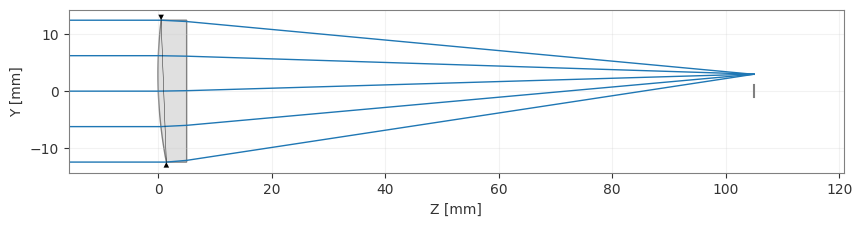

(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

In [13]:
lens.draw(num_rays=5)

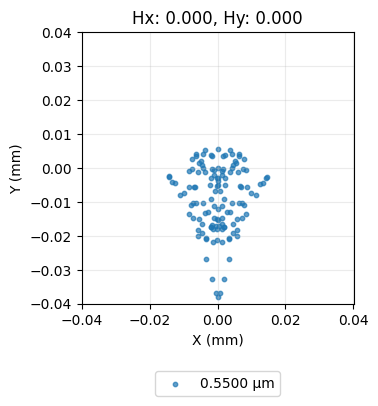

(<Figure size 1200x400 with 1 Axes>,
 [<Axes: title={'center': 'Hx: 0.000, Hy: 0.000'}, xlabel='X (mm)', ylabel='Y (mm)'>])

In [14]:
spot = analysis.SpotDiagram(lens)
spot.view()

We clearly see that the front surface of our lens appears to be tilted, which forces the on-axis rays to intercept the image plane near y=3mm.

Conclusions:

- We introduced freeform surfaces in Optiland.
- We optimized a singlet lens for minimal spot size and for an off-axis real ray intercept point.
- Additional freeform surfaces are available and can be found in the optiland.geometries module or the documentation.